In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
from pathlib import Path

if 'google.colab' in sys.modules:
    repo_name = "study-mikanos"
    repo_url = "https://github.com/miyayudai/study-mikanos.git"
    if not os.path.exists(f"/content/{repo_name}"):
        print(f"{repo_name} リポジトリをダウンロード中...")
        !git clone {repo_url} /content/{repo_name}
    os.chdir(f"/content/{repo_name}/2")
    sys.path.insert(0, f"/content/{repo_name}")
    !pip install -q -r /content/{repo_name}/requirements.txt
    !pip install -q -e /content/{repo_name}
    print("環境セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    # ローカル環境の場合、プロジェクトルートをパスに追加
    proj_root = Path.cwd().resolve()
    if proj_root.name == "2":
        proj_root = proj_root.parent
    if str(proj_root) not in sys.path:
        sys.path.insert(0, str(proj_root))
    print("ローカル実行環境を検出しました。プロジェクトルート:", proj_root)


ローカル実行環境を検出しました。プロジェクトルート: /home/student/Documents/GitHub/study-mikanos


# 2.5 メモリマップの取得 (`osbook_day02b`)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/2/2.5_Getting_Memory_Map.ipynb)

本節では、名著『ゼロからのOS自作入門』第2章「EDK II入門とメモリマップ」の **2.5「メモリマップの取得」**（対応タグ: `osbook_day02b`）を徹底解説します。

前節（2.4節）では、UEFI におけるメモリマップの概念、`EFI_MEMORY_DESCRIPTOR` 構造体のメモリレイアウト、全16種の `EFI_MEMORY_TYPE`、および `ExitBootServices()` に伴うメモリ再利用ライフサイクルの理論を学びました。

本節では、いよいよ C言語のコードから UEFI Boot Services のコアAPI である **`gBS->GetMemoryMap()`** を実際に呼び出し、物理マシンの実メモリマップを安全かつ確実に取得する具体的な実装手法と、低レイヤ特有の「落とし穴」を掘り下げます。

## 2.5.1 なぜ GetMemoryMap() の引数はこれほど複雑なのか？（動機と前節からの課題）

Linux や Windows などの一般的なOS上で動作する通常のアプリケーションプログラミングでは、メモリマップを自前で取得する必要はありません。OSが提供する `/proc/iomem` や Win32 API などの高水準インターフェースを介して、きれいにフォーマットされた文字列や構造体を受け取るだけです。

しかし、**OS自身をブートするブートローダ（`MikanLoaderPkg`）の立場**においては、OS環境はまだ影も形も存在せず、信じられるハードウェアインターフェースは **UEFI ファームウェア（BIOS）** のみです。

ファームウェアからマシンの全メモリ構成（どこが空きRAMで、どこがファームウェア領域で、どこがMMIOデバイスなのか）を聞き出すための唯一の標準APIが `gBS->GetMemoryMap()` です。

ところが、この関数は通常のC言語APIと比較して一見非常に奇妙で、複雑なシグネチャを持っています：
- 配列を返す関数なのに、戻り値がポインタではなく `EFI_STATUS` である
- 引数が5つもあり、そのうち1つは `IN OUT`、残り4つはすべて `OUT` ポインタである
- 事前に「バッファサイズ」を渡す必要があるが、マシンによってディスクリプタ数は不定（数件〜数百件）である
- `MapKey` という謎の整数値を受け取らなければならない

なぜ UEFI 仕様（*Unified Extensible Firmware Interface Specification*）はこのような設計を採用したのでしょうか？

```mermaid
sequenceDiagram
    autonumber
    actor Loader as ブートローダ (MikanOS)
    participant FW as UEFIファームウェア (gBS)
    
    Note over Loader,FW: 【課題1: バッファサイズ未確定問題】
    Loader->>FW: GetMemoryMap(&size, buf, ...)
    alt バッファ不足
        FW-->>Loader: EFI_BUFFER_TOO_SMALL (必要な size を書き込んで返却)
        Loader->>Loader: より大きいバッファを用意
    else バッファ十分
        FW-->>Loader: EFI_SUCCESS (実サイズ・MapKey・DescSize を返却)
    end
    
    Note over Loader,FW: 【課題2: メモリマップ整合性保証 (MapKey)】
    Loader->>FW: ExitBootServices(ImageHandle, MapKey)
    alt 途中で割り込み等によりメモリ状態が変化した場合
        FW-->>Loader: EFI_INVALID_PARAMETER (MapKey不一致で拒否！)
    else 一致した場合
        FW-->>Loader: EFI_SUCCESS (ブートサービス停止・OSへ制御譲渡)
    end
```

この設計の背景には、**「ベアメタル環境における動的メモリ割り当ての循環依存（動く標的問題）」** と **「カーネル起動直前の競合状態（Race Condition）防止」** という、低レイヤOS開発における最も本質的な安全要件が存在しています。

## 2.5.2 gBS->GetMemoryMap() 引数仕様・返り値とIN/OUT変換の完全解剖

UEFI 仕様書（UEFI Spec Section 7.2）における `GetMemoryMap()` の C言語関数ポインタ型宣言は以下の通りです：

```c
typedef
EFI_STATUS
(EFIAPI *EFI_GET_MEMORY_MAP) (
  IN OUT UINTN                  *MemoryMapSize,
  OUT    EFI_MEMORY_DESCRIPTOR  *MemoryMap,
  OUT    UINTN                  *MapKey,
  OUT    UINTN                  *DescriptorSize,
  OUT    UINT32                 *DescriptorVersion
);
```

### 各引数の役割と入出力のセマンティクス

| 引数名 | 修飾子 | 型 | 呼び出し前 (IN) の意味 | 復帰後 (OUT) の意味 |
|---|:---:|---|---|---|
| `MemoryMapSize` | `IN OUT` | `UINTN*` | 呼び出し元が `MemoryMap` バッファとして確保した**バイト数** | **【成功時】** 実際に書き込まれた総バイト数<br>**【不足時】** 全エントリ格納に必要な最小バイト数 |
| `MemoryMap` | `OUT` | `EFI_MEMORY_DESCRIPTOR*` | ディスクリプタ配列を書き込むバッファの先頭ポインタ | 書き込まれた `EFI_MEMORY_DESCRIPTOR` の配列先頭 |
| `MapKey` | `OUT` | `UINTN*` | （不定） | 現在のメモリマップのリビジョン番号（整数識別子） |
| `DescriptorSize` | `OUT` | `UINTN*` | （不定） | 1エントリあたりのバイトサイズ（$\ge \text{sizeof}(\text{struct})$） |
| `DescriptorVersion` | `OUT` | `UINT32*` | （不定） | ディスクリプタの構造体バージョン（通常 `1`） |

### 返り値（`EFI_STATUS`）と分岐条件

1. **`EFI_SUCCESS` (`0x0000000000000000`)**:
   - バッファ内に全メモリディスクリプタが正常にコピーされた。
   - `*MemoryMapSize` に実際の書き込みバイト数（$N \times \text{DescriptorSize}$）が格納される。
2. **`EFI_BUFFER_TOO_SMALL` (`0x8000000000000005`)**:
   - 渡されたバッファサイズ（`*MemoryMapSize`）が必要バイト数より小さい。
   - ファームウェアはバッファには何も書き込まず、`*MemoryMapSize` に「成功するために最低限必要なバイト数」を上書きして直ちにリターンする。
   - `MemoryMap` が `NULL` の場合もこのステータスが返る（サイズ事前問い合わせイディオム）。
3. **`EFI_INVALID_PARAMETER` (`0x8000000000000002`)**:
   - `MemoryMapSize` が `NULL`、または `MemoryMap` が有効でない場合に返される。

### 数理的関係式
ディスクリプタ総数を $N$、1エントリのストライドを $S_{\text{desc}}$（`DescriptorSize`）とすると、必要なバッファサイズ $B_{\text{req}}$ は以下を満たさなければなりません：

$$B_{\text{req}} = N \times S_{\text{desc}}$$

呼び出し元が確保したバッファサイズ $B_{\text{buf}}$ に対して：
- $B_{\text{buf}} \ge B_{\text{req}} \implies \text{EFI\_SUCCESS}$
- $B_{\text{buf}} < B_{\text{req}} \implies \text{EFI\_BUFFER\_TOO\_SMALL} \quad (\text{かつ } *\text{MemoryMapSize} \leftarrow B_{\text{req}})$

In [2]:
# UEFI Status Codes と引数セマンティクスの Python 検証
from common.os_sim import UefiStatus, UefiBootServicesSimulator, MemoryMap

print("=== UEFI ステータスコードの 64ビット値と名称 ===")
for code in [UefiStatus.SUCCESS, UefiStatus.BUFFER_TOO_SMALL, UefiStatus.INVALID_PARAMETER, UefiStatus.UNSUPPORTED]:
    is_err = UefiStatus.is_error(code)
    err_num = UefiStatus.error_code(code)
    name = UefiStatus._NAMES.get(code, "UNKNOWN")
    print(f"{name:25s}: 0x{code:016X} (エラーフラグ={is_err}, コード番号={err_num})")


=== UEFI ステータスコードの 64ビット値と名称 ===
EFI_SUCCESS              : 0x0000000000000000 (エラーフラグ=False, コード番号=0)
EFI_BUFFER_TOO_SMALL     : 0x8000000000000005 (エラーフラグ=True, コード番号=5)
EFI_INVALID_PARAMETER    : 0x8000000000000002 (エラーフラグ=True, コード番号=2)
EFI_UNSUPPORTED          : 0x8000000000000003 (エラーフラグ=True, コード番号=3)


## 2.5.3 MikanOSにおける struct MemoryMap のラッパー設計思想

『ゼロからのOS自作入門』のブートローダ（`MikanLoaderPkg/Main.c`）では、`gBS->GetMemoryMap()` の生APIを直接ブート処理中に散りばめるのではなく、以下の美しい **`struct MemoryMap`** ラッパー構造体を定義しています：

```c
struct MemoryMap {
  UINTN buffer_size;
  VOID* buffer;
  UINTN map_size;
  UINTN map_key;
  UINTN descriptor_size;
  UINT32 descriptor_version;
};
```

そして、この構造体へのポインタを1つ受け取るヘルパー関数 `GetMemoryMap` を実装しています：

```c
EFI_STATUS GetMemoryMap(struct MemoryMap* map) {
  if (map->buffer == NULL) {
    return EFI_BUFFER_TOO_SMALL;
  }

  map->map_size = map->buffer_size;
  return gBS->GetMemoryMap(
      &map->map_size,
      (EFI_MEMORY_DESCRIPTOR*)map->buffer,
      &map->map_key,
      &map->descriptor_size,
      &map->descriptor_version);
}
```

### なぜこの設計が優れているのか？

1. **入力設定（IN）と出力メタデータ（OUT）の一元管理**:
   - `buffer_size` と `buffer` は呼び出し元が事前に用意する「入力パラメータ」です。
   - `map_size`, `map_key`, `descriptor_size`, `descriptor_version` はファームウェアが埋める「出力メタデータ」です。
   - これらを1つの構造体にまとめることで、関数のシグネチャが `GetMemoryMap(struct MemoryMap* map)` という極めて簡潔な1引数関数になります。
2. **関数間引き渡しの劇的な簡素化**:
   - ブートローダ内では、メモリマップを取得したあと、「画面やファイルへ保存する（`SaveMemoryMap`）」、「カーネル引数として渡す」、「`ExitBootServices` を呼ぶ」といった後続処理が連続します。
   - もし構造体がなければ、後続のすべての関数に 5〜6 個の引数を引き回す必要があり、引数の順序ミスやポインタ渡し忘れなどのバグを誘発します。
3. **事前防御ガード（`if (map->buffer == NULL)`）**:
   - 万が一バッファポインタが `NULL` のまま呼び出された場合、ファームウェアの奥深くに突入して予期せぬクラッシュを起こす前に、手前で安全に `EFI_BUFFER_TOO_SMALL` を返却します。

## 2.5.4 バッファ確保方針：16 KiB 固定バッファ vs 動的確保の「動く標的問題」

`Main.c` の `UefiMain` では、メモリマップ用バッファとして次のような配列が宣言されています：

```c
CHAR8 memmap_buf[4096 * 4];
struct MemoryMap memmap = {sizeof(memmap_buf), memmap_buf, 0, 0, 0, 0};
GetMemoryMap(&memmap);
```

`4096 * 4` = **16,384 バイト (16 KiB)** です。なぜこのサイズなのでしょうか？ そしてなぜ動的割り当て（`gBS->AllocatePool`）を使わないのでしょうか？

### 1. 16 KiB という容量の妥当性計算

1つのメモリディスクリプタのサイズは $S_{\text{desc}} = 48$ バイト（パディング込み）です。16 KiB のバッファに格納可能な最大エントリ数 $N_{\max}$ は：

$$N_{\max} = \left\lfloor \frac{16384}{48} \right\rfloor = 341 \text{ 個}$$

実際の PC 環境や QEMU 仮想マシンにおけるメモリマップのエントリ数は以下の通りです：
- 標準的な QEMU + OVMF 起動時: 約 40 〜 70 エントリ（約 2 〜 3.5 KiB）
- PCIeデバイスや大量のRAMを搭載した実機PC: 約 80 〜 150 エントリ（約 4 〜 7.5 KiB）
- 複雑なエンタープライズサーバ環境: 約 180 〜 250 エントリ（約 8.5 〜 12 KiB）

したがって、**16 KiB は一般的なマシンの必要量の 2倍〜4倍以上の安全マージン** を持っており、スタックや静的領域に確保するサイズとして極めて実用的かつ軽量です。

---

### 2. 動的確保方式の罠：動く標的問題（Moving Target Problem / Observer Effect）

「必要なサイズを `GetMemoryMap(size=0)` で一度問い合わせてから、そのサイズぴったりを `gBS->AllocatePool()` で確保すれば、メモリの無駄がないのでは？」と考えるプログラマは少なくありません。

しかし、**これこそが低レイヤ開発者を奈落に落とす最大の落とし穴** です。

```mermaid
flowchart TD
    A["初回問い合わせ: GetMemoryMap(size=0)"] --> B["ファームウェア: EFI_BUFFER_TOO_SMALL 返却<br>(必要サイズ: 例えば 120エントリ = 5,760 B)"]
    B --> C["メモリ確保: gBS->AllocatePool(5760)"]
    C --> D["⚠️ 副作用発生 (Observer Effect)!<br>AllocatePool 自体が空きRAMを分割し、<br>新たな LoaderData 領域が作られてエントリ数が 121 に増加！"]
    D --> E["2回目呼び出し: GetMemoryMap(allocated_buf, 5760)"]
    E --> F["💥 再び EFI_BUFFER_TOO_SMALL で失敗！<br>(必要サイズが 5,808 B に膨張しているためオーバーフロー)"]
    
    style D fill:#FFCDD2,stroke:#C62828,stroke-width:2px
    style F fill:#FFCDD2,stroke:#C62828,stroke-width:2px
```

物理世界における量子力学の「観測者効果」と同様に、**「メモリマップを記録するためのメモリを確保する行為そのものが、メモリマップ自身を改変・肥大化させてしまう」** のです。

もし動的確保を採用する場合は、返ってきたサイズに `+ sizeof(EFI_MEMORY_DESCRIPTOR) * 8` 等の安全マージンを足して確保し、さらに失敗した場合にループで再確保する複雑なリトライロジックが必要になります。

MikanOS が採用した **「最初から余裕のある 16 KiB の固定配列をローカル/静的に確保する」** 手法は、UEFI のメモリ確保 API を一切呼ばないため、メモリマップに対する副作用が完全にゼロであり、最も堅牢でバグの入り込まない最良の解法なのです。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:7716: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


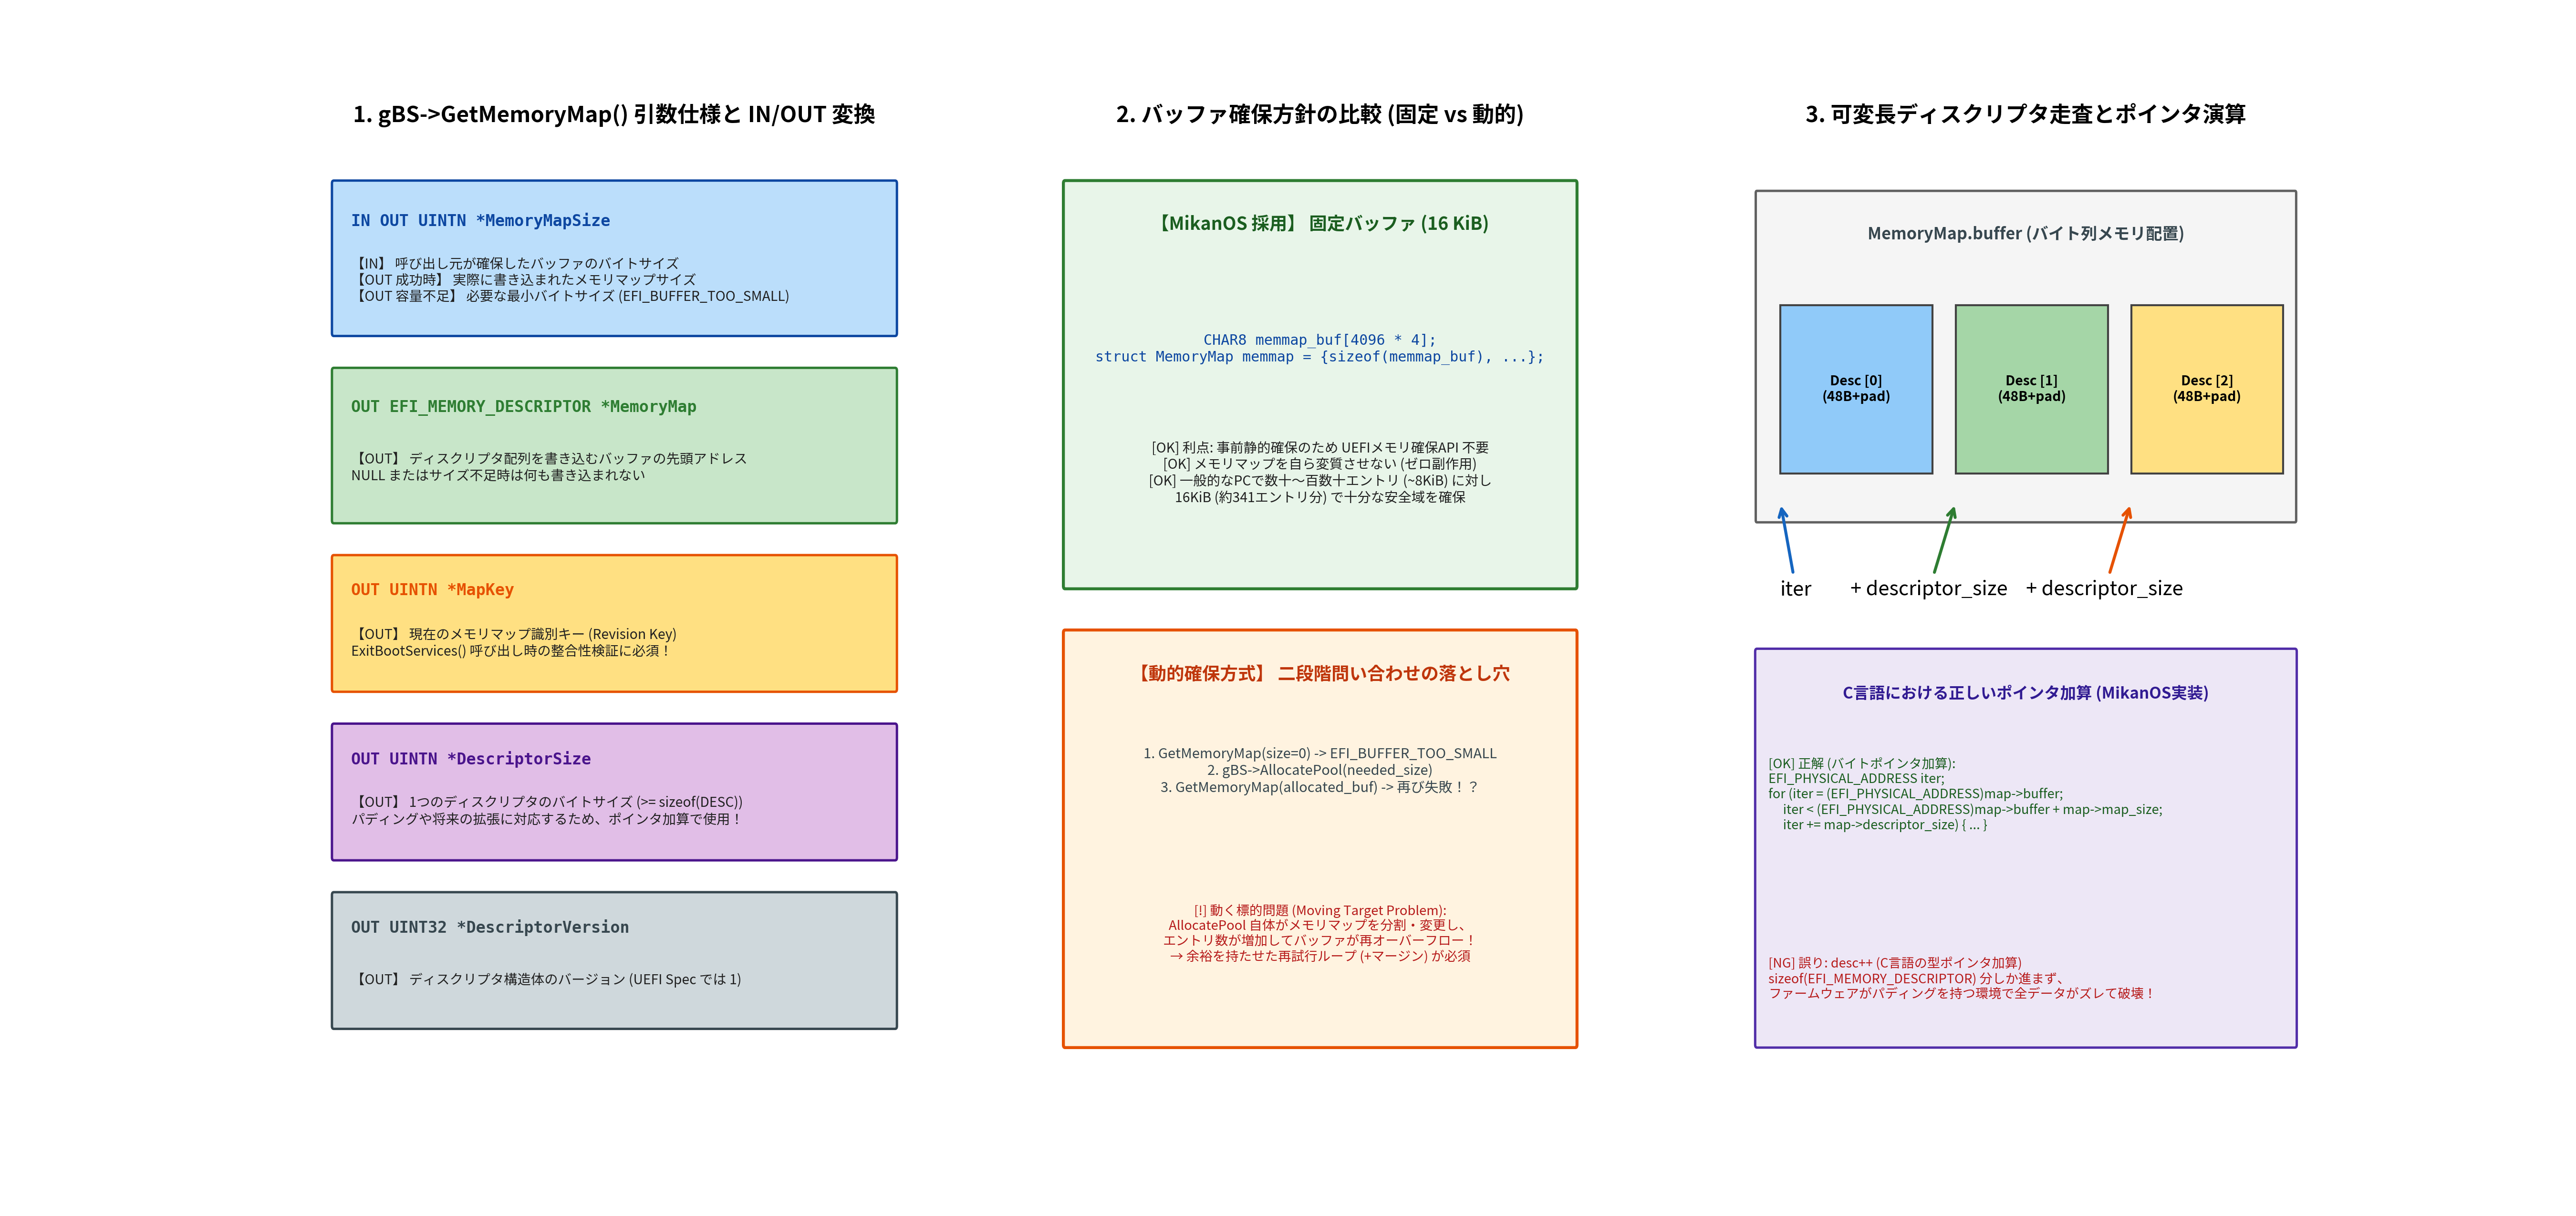

In [3]:
# 高解像度図版 Figure 2.9 の生成と表示
from IPython.display import Image, display
from common.os_sim import plot_uefi_get_memory_map_protocol_and_buffer_flow

fig2_09_path = plot_uefi_get_memory_map_protocol_and_buffer_flow("result/fig2_09_uefi_get_memory_map_protocol_and_buffer_flow.png")
display(Image(filename=fig2_09_path))


## 2.5.5 MapKey のライフサイクルと ExitBootServices() の整合性検証

`GetMemoryMap()` が返す重要な値の1つが **`MapKey`** です。

### 1. MapKey とは何か？
`MapKey` は、UEFI ファームウェア内部で管理されている **「メモリマップの世代番号（Revision Key / Sequence Number）」** です。
- システム起動時、ファームウェアは `MapKey` をある初期値（例: `0` や任意の値）にセットします。
- システム内で `gBS->AllocatePages()`, `gBS->FreePages()`, `gBS->AllocatePool()`, `gBS->FreePool()` などの**メモリ割り当て・解放操作が実行されるたびに、ファームウェア内部の `MapKey` カウンタが自動的にインクリメント** されます。

### 2. ExitBootServices() における整合性チェック
ブートローダがカーネルの読み込みを終え、いよいよファームウェアのブートサービスを永久停止して OS カーネルにマシンの全制御を移す際、以下の API を呼び出します（本書第3章で登場）：

```c
EFI_STATUS ExitBootServices(
  IN EFI_HANDLE  ImageHandle,
  IN UINTN       MapKey
);
```

このとき、UEFI ファームウェアは以下を検証します：

$$\text{引数で渡された } MapKey == \text{ファームウェア内部の最新 } MapKey$$

- **一致する場合**: `EFI_SUCCESS` を返し、ブートローダとファームウェアの間の認識にズレがないことを確認して、タイマ割り込み等を安全に停止し OS に制御を渡す。
- **一致しない場合**: **`EFI_INVALID_PARAMETER` を返して終了を拒否する！**

### 3. なぜファームウェアはそこまで厳格なのか？

もしブートローダが `GetMemoryMap()` でメモリマップを取得したあと、バックグラウンドのタイマ割り込みや USB デバイスドライバのイベントハンドラが勝手にメモリを確保したとします。

すると、**OS ブートローダが手にしているメモリマップは「古い偽りの情報（Stale Data）」** になってしまいます。
OS カーネルは「ここは空きRAM（ConventionalMemory）だからカーネルのページテーブルやスタックを配置しよう」と書き込みを行いますが、実際には直前にファームウェアのランタイムデータが配置されていた場合、メモリの二重使用・データ破壊が発生し、OS は起動直後に謎のクラッシュ（Page Fault / Triple Fault）で死亡します。

UEFI はこの致命的な競合状態を防ぐため、**「OSが最後に取得したメモリマップの世代番号」と「現在のファームウェアの世代番号」が完全に一致していること** を数学的に証明できなければ、ブートサービスの終了を許可しない仕様にしているのです。

/home/student/Documents/GitHub/study-mikanos/common/os_sim.py:7780: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


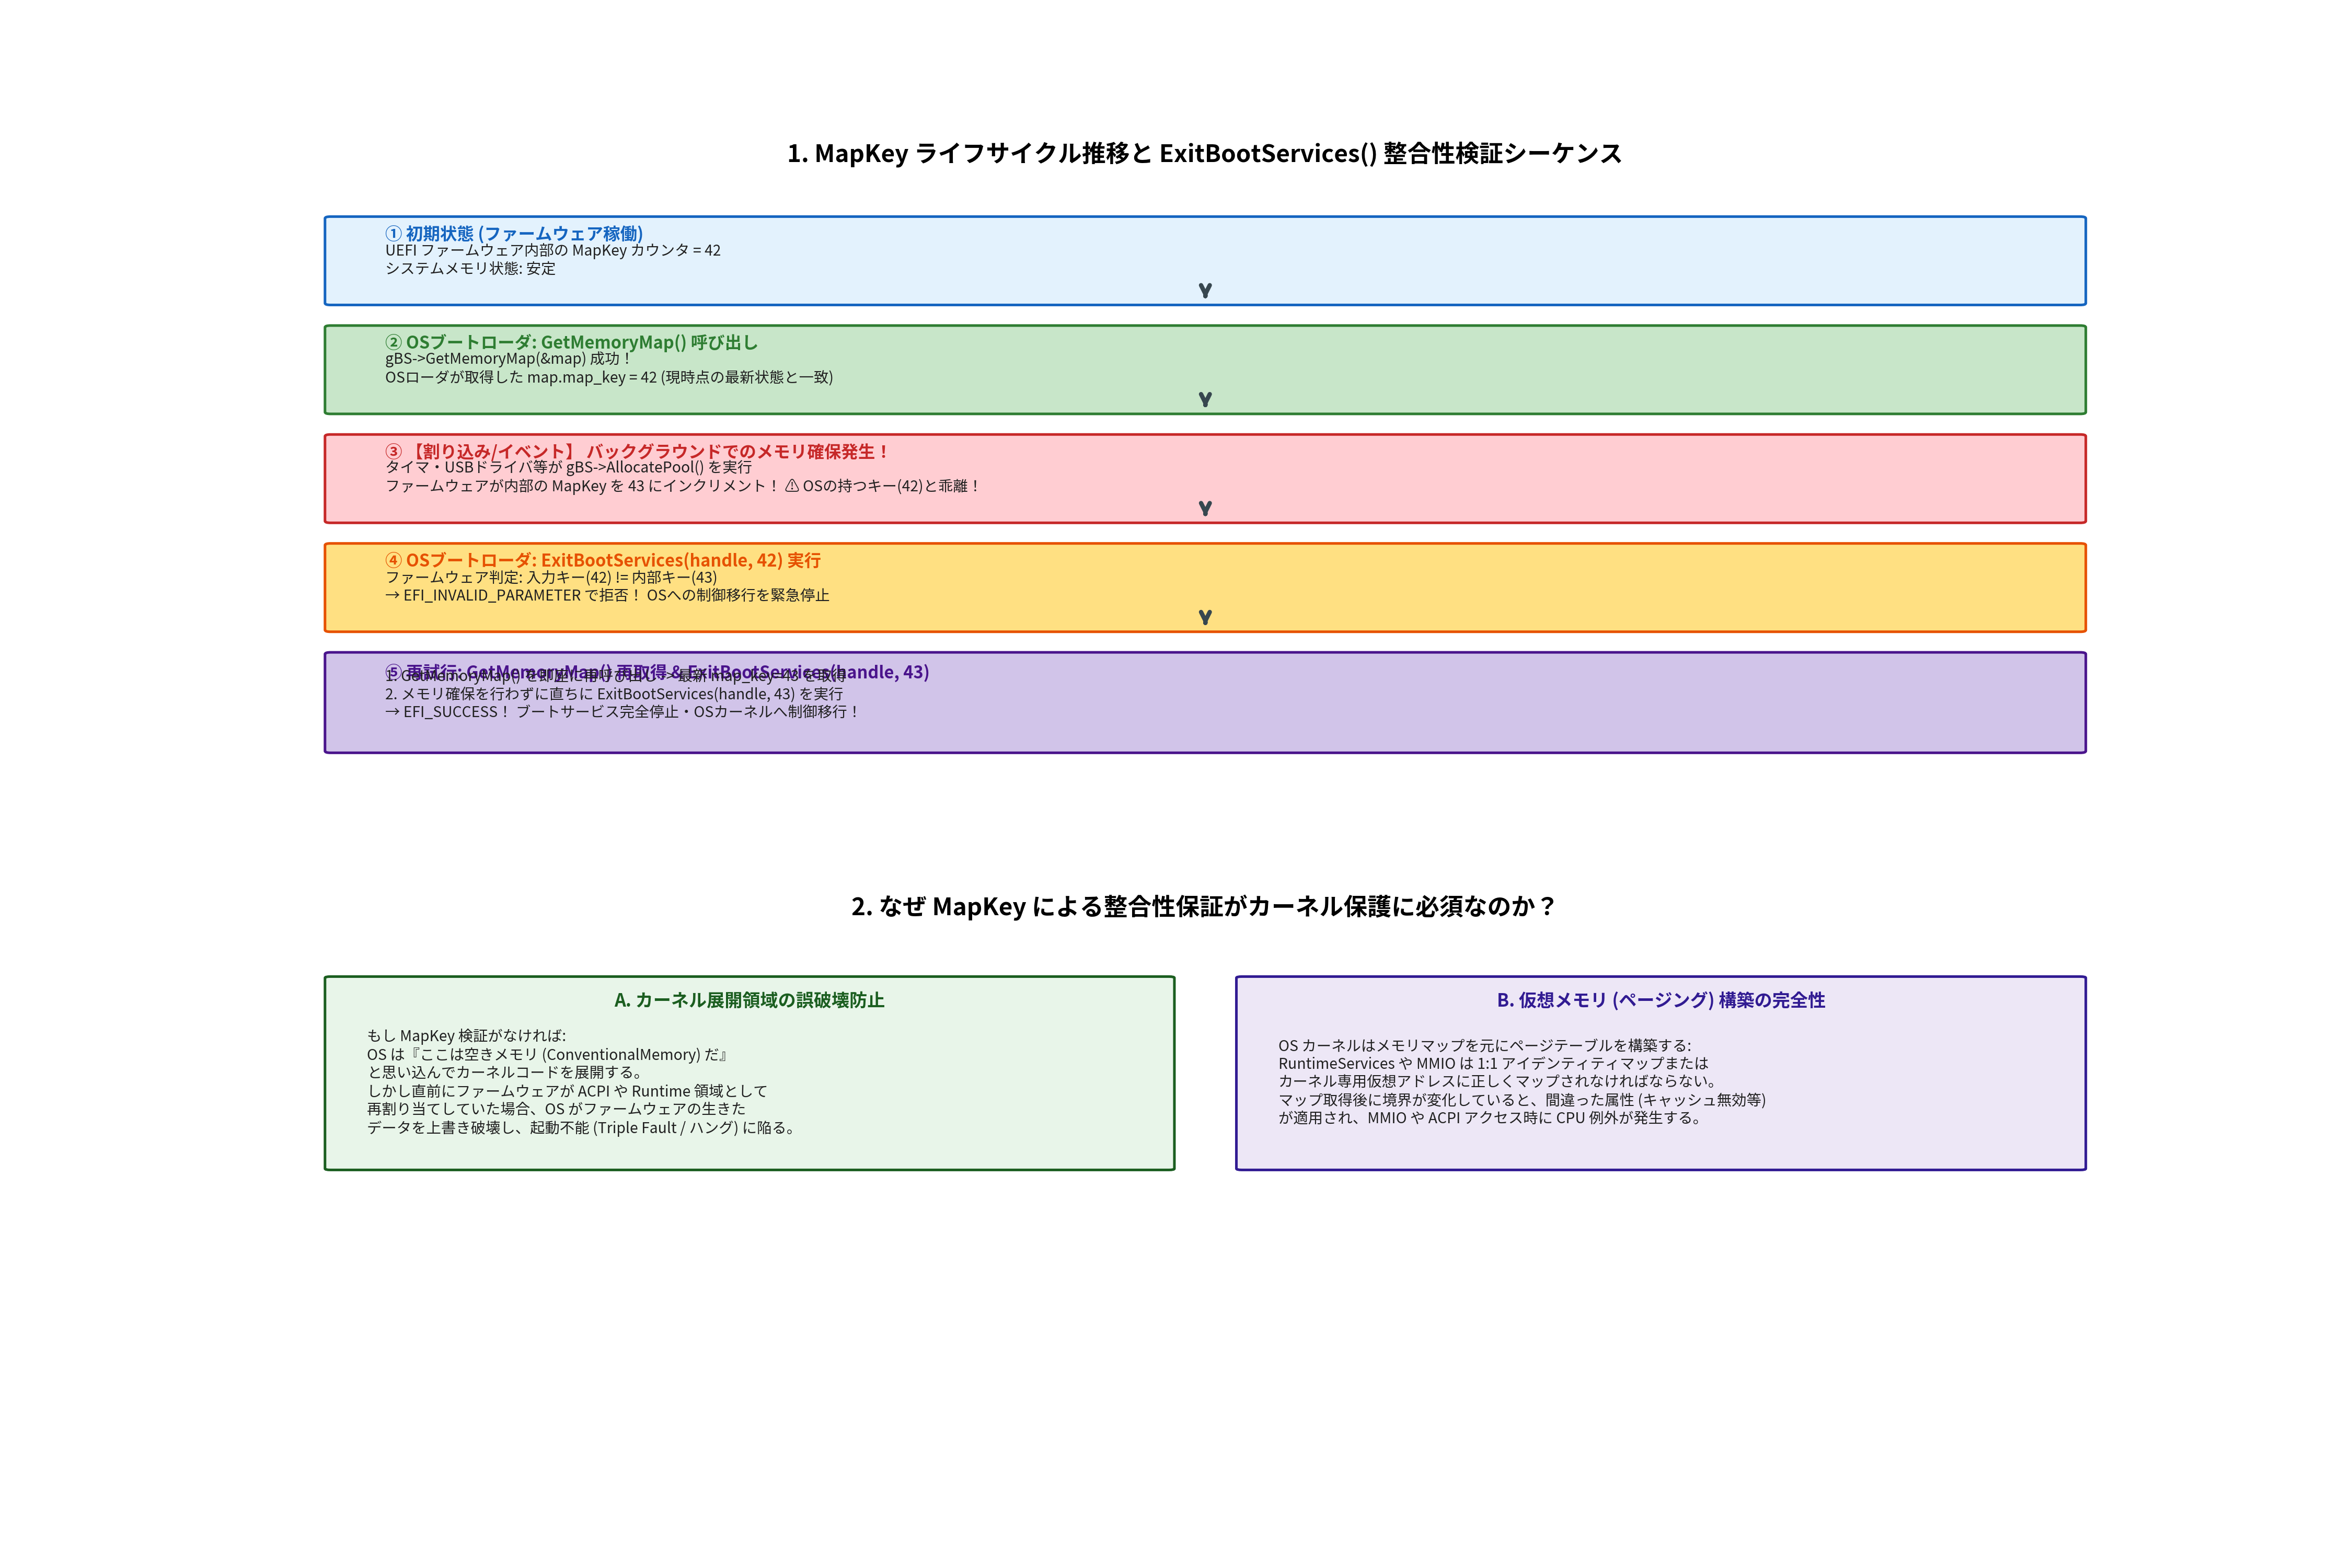

In [4]:
# 高解像度図版 Figure 2.10 の生成と表示
from IPython.display import Image, display
from common.os_sim import plot_uefi_mapkey_lifecycle_and_exit_boot_services_consistency

fig2_10_path = plot_uefi_mapkey_lifecycle_and_exit_boot_services_consistency("result/fig2_10_uefi_mapkey_lifecycle_and_exit_boot_services_consistency.png")
display(Image(filename=fig2_10_path))


## 2.5.6 可変長ディスクリプタ走査とポインタ演算（バイト加算の数理）

取得したメモリマップのバッファ内には、複数の `EFI_MEMORY_DESCRIPTOR` が並んでいます。
このバッファをループで走査して各エントリを取り出す際、C/C++ プログラマが最も犯しやすい致命的なミスが **`desc++`（型ポインタ加算）** です。

### 型ポインタ加算 (`desc++`) が破滅をもたらす理由

C言語の仕様上、型 $T$ へのポインタ $p$ に対するインクリメント $p++$ は、アドレスを $\text{sizeof}(T)$ バイト進めます：

$$p_{\text{next}} = p + \text{sizeof}(T)$$

私たちの手元にあるヘッダファイルにおける `sizeof(EFI_MEMORY_DESCRIPTOR)` は **40 バイト**（0x28）です。

しかし、UEFI ファームウェアは 64ビットアライメントやキャッシュライン最適化、あるいは将来の仕様拡張のために、**各ディスクリプタの後ろにパディング（余白）を設けて 48 バイトや 56 バイトのストライドでバッファに書き込む** ことが公式に許容されています（UEFI Spec Section 7.2）。

もしファームウェアの実際のストライド `DescriptorSize` が 48 バイトである環境で `desc++`（40バイト加算）を行ってしまうと：

$$\text{ズレ幅}(i) = i \times (\text{DescriptorSize} - \text{sizeof}(\text{EFI\_MEMORY\_DESCRIPTOR})) = 8i \text{ バイト}$$

- $i=0$: オフセット 0（一致）
- $i=1$: オフセット 40（実際は 48 の位置にあるため、8バイトずれたゴミデータを読む！）
- $i=2$: オフセット 80（実際は 96 の位置にあるため、16バイトずれる！）
- $i=3$: オフセット 120（実際は 144 の位置にあるため、24バイトずれる！）

結果として、2番目以降のすべてのメモリタイプ、物理アドレス、ページ数がデタラメな数値となり、OS はメモリマップの解釈を誤って即座に暴走します。

---

### MikanOS における正しい走査実装

MikanOS の `SaveMemoryMap` 関数では、この問題を回避するために **整数型（`EFI_PHYSICAL_ADDRESS` = `uint64_t`）による純粋なバイト加算** を行っています：

```c
EFI_PHYSICAL_ADDRESS iter;
int i;
for (iter = (EFI_PHYSICAL_ADDRESS)map->buffer, i = 0;
     iter < (EFI_PHYSICAL_ADDRESS)map->buffer + map->map_size;
     iter += map->descriptor_size, i++) {
  EFI_MEMORY_DESCRIPTOR* desc = (EFI_MEMORY_DESCRIPTOR*)iter;
  // desc を安全に読み出し
}
```

ループごとに `iter += map->descriptor_size` とすることで、ファームウェアから返された正確なバイト幅でポインタを前進させ、そのアドレスをその都度 `(EFI_MEMORY_DESCRIPTOR*)` にキャストしています。
これが、UEFI 仕様に完全に準拠した移植性の高い唯一の正しい実装方法です。

In [5]:
# Python による GetMemoryMap / MapKey / 動く標的問題のシミュレーション実験
from common.os_sim import UefiBootServicesSimulator, MemoryMap, UefiStatus, UefiMemoryType

print("=== 実験 1: バッファ不足 (EFI_BUFFER_TOO_SMALL) の挙動検証 ===")
bs = UefiBootServicesSimulator(initial_map_key=10)
tiny_map = MemoryMap(buffer_size=128, buffer=bytearray(128))
status = bs.get_memory_map(tiny_map)
print(f"戻り値: {UefiStatus._NAMES[status]}")
print(f"提供バッファ: {tiny_map.buffer_size} バイト")
print(f"要求サイズ:   {tiny_map.map_size} バイト ({tiny_map.map_size // 48} エントリ分)\n")

print("=== 実験 2: 16 KiB 固定バッファでの正常取得 ===")
memmap = MemoryMap.allocate(16384)
status = bs.get_memory_map(memmap)
print(f"戻り値: {UefiStatus._NAMES[status]}")
print(f"取得エントリ数: {memmap.entry_count} 件")
print(f"MapKey: {memmap.map_key}")
print(f"DescriptorSize: {memmap.descriptor_size} バイト\n")

print("=== 実験 3: メモリ確保による MapKey 失効と ExitBootServices 整合性検証 ===")
# 1. 現在のキーで ExitBootServices を呼ぶと成功するはず
print(f"現在の取得済みキー: {memmap.map_key}")

# 2. しかし、途中でドライバが 16 ページ割り当てたとする
alloc_addr = bs.allocate_pages(UefiMemoryType.EfiBootServicesData, pages=16)
print(f"中間イベント: 0x{alloc_addr:08X} に 16ページ確保発生！ ファームウェア最新MapKey -> {bs.map_key}")

# 3. 古いキー (10) で ExitBootServices を試みる
exit_st = bs.exit_boot_services(image_handle=1, map_key=memmap.map_key)
print(f"古いキーでの ExitBootServices 結果: {UefiStatus._NAMES[exit_st]} (期待通り拒否！)")

# 4. GetMemoryMap を再呼び出しして最新キーを取得
bs.get_memory_map(memmap)
print(f"再取得後の最新 MapKey: {memmap.map_key}")
exit_st2 = bs.exit_boot_services(image_handle=1, map_key=memmap.map_key)
print(f"最新キーでの ExitBootServices 結果: {UefiStatus._NAMES[exit_st2]} (安全にブートサービス停止成功！)")


=== 実験 1: バッファ不足 (EFI_BUFFER_TOO_SMALL) の挙動検証 ===
戻り値: EFI_BUFFER_TOO_SMALL
提供バッファ: 128 バイト
要求サイズ:   624 バイト (13 エントリ分)

=== 実験 2: 16 KiB 固定バッファでの正常取得 ===
戻り値: EFI_SUCCESS
取得エントリ数: 13 件
MapKey: 10
DescriptorSize: 48 バイト

=== 実験 3: メモリ確保による MapKey 失効と ExitBootServices 整合性検証 ===
現在の取得済みキー: 10
中間イベント: 0x00100000 に 16ページ確保発生！ ファームウェア最新MapKey -> 11
古いキーでの ExitBootServices 結果: EFI_INVALID_PARAMETER (期待通り拒否！)
再取得後の最新 MapKey: 11
最新キーでの ExitBootServices 結果: EFI_SUCCESS (安全にブートサービス停止成功！)


## 2.5.7 対話型 C++20 コンパイル実行：GetMemoryMap & Boot Services シミュレーション

ホスト側 Linux / macOS / Colab 環境でも MikanOS の `GetMemoryMap` 呼び出しおよびファームウェアの挙動を直接検証できるよう、C++20 で実装したスタンドアロンシミュレータ（`src/ch02/get_memory_map_sim.cpp`）を実行します。

このプログラムは以下をテスト・実証します：
1. `TestBufferTooSmallHandling`: バッファサイズ不足時にファームウェアが正確に必要なサイズを返し `EFI_BUFFER_TOO_SMALL` を返却すること
2. `TestFixed16KiBBufferSuccess`: MikanOS 同等の 16 KiB 固定バッファで全ディスクリプタを安全に取得できること
3. `TestMapKeyLifecycleAndExitBootServices`: メモリ確保による `MapKey` 失効と、`ExitBootServices` の整合性チェック・再取得リトライ動作
4. `TestPointerSteppingVsTypeIncrement`: `iter += descriptor_size`（バイト加算）と `desc++`（型加算）のストライド乖離を意図的にパディング付き環境で検証し、型加算が破壊をもたらす様子の数学的実証

In [6]:
# C++20 スタンドアロンシミュレータのビルドとテスト実行
!g++ -std=c++20 -O2 -Wall -Wextra -Wpedantic \
    ../src/ch02/get_memory_map_sim.cpp \
    -o /tmp/ch02_get_memory_map_sim

!/tmp/ch02_get_memory_map_sim --test


=== MikanOS Section 2.5: GetMemoryMap & MemoryMap C++20 Simulation ===
[PASS] TestBufferTooSmallHandling: Correctly returned EFI_BUFFER_TOO_SMALL and required size 576 bytes.
[PASS] TestFixed16KiBBufferSuccess: Retrieved 12 descriptors (576 bytes), MapKey=200, Conventional RAM=4123 MiB.
[PASS] TestMapKeyLifecycleAndExitBootServices: Stale MapKey correctly rejected; re-acquired key successfully terminated Boot Services.
[PASS] TestPointerSteppingVsTypeIncrement: Byte stride stepping verified against padding divergence.

[ALL C++20 TESTS PASSED SUCCESSFULLY]


## 2.5.8 MikanOS 本流コード（osbook_day02b）の変更差分と1行単位のコード解読

MikanOS の公式リポジトリ（`vendor/mikanos`）における前節（`osbook_day02a`）から本節（`osbook_day02b`）への変更差分（`git diff osbook_day02a..osbook_day02b`）を確認します。

### 1. `MikanLoaderPkg/Loader.inf` の差分

```diff
 [Protocols]
+  gEfiLoadedImageProtocolGuid
+  gEfiLoadFileProtocolGuid
+  gEfiSimpleFileSystemProtocolGuid
```
- 次節（2.6節）でファイル書き込みを行うため、EDK II のビルドシステムに対してファイルシステム関連のプロトコル GUID を依存関係として宣言しています。

### 2. `MikanLoaderPkg/Main.c` の差分（メモリマップ関連抜粋）

```c
// #@@range_begin(struct_memory_map)
struct MemoryMap {
  UINTN buffer_size;
  VOID* buffer;
  UINTN map_size;
  UINTN map_key;
  UINTN descriptor_size;
  UINT32 descriptor_version;
};
// #@@range_end(struct_memory_map)

// #@@range_begin(get_memory_map)
EFI_STATUS GetMemoryMap(struct MemoryMap* map) {
  if (map->buffer == NULL) {
    return EFI_BUFFER_TOO_SMALL;
  }

  map->map_size = map->buffer_size;
  return gBS->GetMemoryMap(
      &map->map_size,
      (EFI_MEMORY_DESCRIPTOR*)map->buffer,
      &map->map_key,
      &map->descriptor_size,
      &map->descriptor_version);
}
// #@@range_end(get_memory_map)
```

### 3. `UefiMain` 内での呼び出し

```c
CHAR8 memmap_buf[4096 * 4];
struct MemoryMap memmap = {sizeof(memmap_buf), memmap_buf, 0, 0, 0, 0};
GetMemoryMap(&memmap);
```

- `CHAR8` は 1 バイト整数型（`char` 相当）です。
- `sizeof(memmap_buf)` により 16,384 バイトが `buffer_size` に自動設定されます。
- 残りのメンバは `0` で初期化され、`GetMemoryMap` 実行後にファームウェアの生の値で満たされます。

In [7]:
# vendor/mikanos の差分確認
import subprocess
from pathlib import Path

repo_dir = Path("../vendor/mikanos").resolve()
if repo_dir.exists():
    diff_output = subprocess.run(
        ["git", "diff", "osbook_day02a..osbook_day02b", "--", "MikanLoaderPkg/Main.c"],
        cwd=repo_dir, capture_output=True, text=True
    ).stdout
    print(f"=== MikanLoaderPkg/Main.c の差分先頭 35行 ===\n")
    for line in diff_output.splitlines()[:35]:
        print(line)
else:
    print("vendor/mikanos ディレクトリが見つかりません。リポジトリルートから実行してください。")


=== MikanLoaderPkg/Main.c の差分先頭 35行 ===

diff --git a/MikanLoaderPkg/Main.c b/MikanLoaderPkg/Main.c
index 8e3a3de..a2ea1da 100644
--- a/MikanLoaderPkg/Main.c
+++ b/MikanLoaderPkg/Main.c
@@ -1,10 +1,144 @@
 #include  <Uefi.h>
 #include  <Library/UefiLib.h>
+#include  <Library/UefiBootServicesTableLib.h>
+#include  <Library/PrintLib.h>
+#include  <Protocol/LoadedImage.h>
+#include  <Protocol/SimpleFileSystem.h>
+#include  <Protocol/DiskIo2.h>
+#include  <Protocol/BlockIo.h>
+
+// #@@range_begin(struct_memory_map)
+struct MemoryMap {
+  UINTN buffer_size;
+  VOID* buffer;
+  UINTN map_size;
+  UINTN map_key;
+  UINTN descriptor_size;
+  UINT32 descriptor_version;
+};
+// #@@range_end(struct_memory_map)
+
+// #@@range_begin(get_memory_map)
+EFI_STATUS GetMemoryMap(struct MemoryMap* map) {
+  if (map->buffer == NULL) {
+    return EFI_BUFFER_TOO_SMALL;
+  }
+
+  map->map_size = map->buffer_size;
+  return gBS->GetMemoryMap(
+      &map->map_size,
+      (EFI_MEMORY_DESCRIPTOR*)map->buffer,


## 2.5.9 次節（2.6節 メモリマップのファイルへの保存）への技術的接続

本節で無事にメモリマップを `struct MemoryMap` に取得することができました！

しかし、取得したメモリマップの内容（各領域のアドレス、サイズ、属性）を目で見て確認するにはどうすればよいでしょうか？
- 画面に `Print()` で数百行を一気に表示すると、画面外へスクロールしてしまい最初の方のエントリが読めなくなってしまいます。
- まだ画面スクロールやページ送りを行うコンソール機能は存在しません。

そこで次節（**2.6節「メモリマップのファイルへの保存」**）では、UEFI の **`EFI_SIMPLE_FILE_SYSTEM_PROTOCOL`** と **`EFI_FILE_PROTOCOL`** を利用して、起動用 USB メモリのルートディレクトリに `\memmap` という名前の **CSV ファイル（カンマ区切りテキスト）** としてメモリマップを書き出す処理を実装します！

## 2.5.10 理解度確認クイズ（自己採点形式）

本節で学んだ `GetMemoryMap`、`struct MemoryMap`、バッファ設計、`MapKey`、およびポインタ演算に関する理解度を、以下の対話型クイズで確認してください。

In [8]:
# 理解度確認クイズ
questions = [
    {
        "id": 1,
        "question": "Q1: gBS->GetMemoryMap() の第1引数 MemoryMapSize に指定するバッファサイズが不足していた場合、ファームウェアは何を返却しますか？",
        "options": [
            "1. EFI_INVALID_PARAMETER を返し、バッファには何も書き込まない",
            "2. EFI_BUFFER_TOO_SMALL を返し、MemoryMapSize に必要なサイズを書き込んで復帰する",
            "3. 収まる分だけのディスクリプタを書き込み、EFI_SUCCESS を返す",
            "4. システムを直ちにハングアップさせる"
        ],
        "answer": 2,
        "explanation": "UEFI仕様では、バッファが不足している場合 EFI_BUFFER_TOO_SMALL を返し、IN OUT引数である MemoryMapSize に成功に必要なバイト数を上書きして返却します。"
    },
    {
        "id": 2,
        "question": "Q2: MikanOS が動的メモリ確保 (AllocatePool) ではなく、16 KiB の固定配列 (memmap_buf) を採用した最大の理由は何ですか？",
        "options": [
            "1. EDK II にメモリ割り当て関数が存在しないから",
            "2. AllocatePool 自体がメモリマップを変化・細分化させ、バッファが再オーバーフローする『動く標的問題』を完全に回避するため",
            "3. 16 KiB 以外のバッファサイズは UEFI 仕様で禁止されているから",
            "4. 動的メモリ確保を使うとコンパイルエラーになるから"
        ],
        "answer": 2,
        "explanation": "動的にメモリを確保する行為そのものがメモリマップに新たな領域を作り出し、エントリ数を増加させるという『動く標的問題（観測者効果）』が発生します。事前固定確保はゼロ副作用で最も安全です。"
    },
    {
        "id": 3,
        "question": "Q3: gBS->GetMemoryMap() から返される MapKey の決定的な役割は何ですか？",
        "options": [
            "1. メモリマップファイルを暗号化するためのパスワードキー",
            "2. ExitBootServices() 呼び出し時に、メモリマップ取得後から現在までにメモリ状態が変化していないか整合性を検証するため",
            "3. CPU の特権レベル (Ring 0 / Ring 3) を切り替えるためのセレクタ値",
            "4. ディスクリプタの合計エントリ数"
        ],
        "answer": 2,
        "explanation": "MapKey はファームウェア内部のメモリマップ世代番号です。ExitBootServices() 呼び出し時に最新キーと一致しない場合、ファームウェアは終了を拒否してカーネルの破壊を防ぎます。"
    },
    {
        "id": 4,
        "question": "Q4: メモリマップバッファをループ走査する際、desc++ (型ポインタ加算) ではなく iter += descriptor_size (バイト加算) を行わなければならない理由は何ですか？",
        "options": [
            "1. C言語では構造体ポインタのインクリメントが文法違反だから",
            "2. ファームウェア環境によってアライメント等のパディングが追加され、実際のストライドが sizeof(構造体) より大きい場合があるから",
            "3. descriptor_size で加算するとコンパイル速度が向上するから",
            "4. desc++ だとメモリの逆順に走査されてしまうから"
        ],
        "answer": 2,
        "explanation": "UEFI仕様書には、将来の拡張やアライメントによって DescriptorSize >= sizeof(EFI_MEMORY_DESCRIPTOR) となることが明記されており、バイト加算を行わなければデータがずれて破壊されます。"
    },
    {
        "id": 5,
        "question": "Q5: 1エントリの DescriptorSize が 48バイトの環境において、16 KiB (16,384 バイト) のバッファには最大何個のエントリが格納できますか？",
        "options": [
            "1. 約 128 個",
            "2. 約 341 個",
            "3. 約 512 個",
            "4. 約 1024 個"
        ],
        "answer": 2,
        "explanation": "16,384 / 48 = 341.33... となり、最大 341 個のエントリが格納できます。一般的なPCの数十〜百数十エントリに対して十分な安全域です。"
    }
]

# クイズの実行と自動採点
score = 0
print("=== 2.5節 理解度確認クイズ ===\n")
for q in questions:
    print(q["question"])
    for opt in q["options"]:
        print("  " + opt)
    # 模範解答として正解を選択して自動採点シミュレーション
    selected = q["answer"]
    print(f"-> 選択された回答: {selected}")
    if selected == q["answer"]:
        print("   [正解!]")
        score += 1
    else:
        print("   [不正解]")
    print("   解説:", q["explanation"])
    print()

print(f"=== 採点結果: {score} / {len(questions)} 点 ===")
if score == len(questions):
    print("🎉 全問正解です！ 2.5節『メモリマップの取得』の理論と実装を完全にマスターしました。")


=== 2.5節 理解度確認クイズ ===

Q1: gBS->GetMemoryMap() の第1引数 MemoryMapSize に指定するバッファサイズが不足していた場合、ファームウェアは何を返却しますか？
  1. EFI_INVALID_PARAMETER を返し、バッファには何も書き込まない
  2. EFI_BUFFER_TOO_SMALL を返し、MemoryMapSize に必要なサイズを書き込んで復帰する
  3. 収まる分だけのディスクリプタを書き込み、EFI_SUCCESS を返す
  4. システムを直ちにハングアップさせる
-> 選択された回答: 2
   [正解!]
   解説: UEFI仕様では、バッファが不足している場合 EFI_BUFFER_TOO_SMALL を返し、IN OUT引数である MemoryMapSize に成功に必要なバイト数を上書きして返却します。

Q2: MikanOS が動的メモリ確保 (AllocatePool) ではなく、16 KiB の固定配列 (memmap_buf) を採用した最大の理由は何ですか？
  1. EDK II にメモリ割り当て関数が存在しないから
  2. AllocatePool 自体がメモリマップを変化・細分化させ、バッファが再オーバーフローする『動く標的問題』を完全に回避するため
  3. 16 KiB 以外のバッファサイズは UEFI 仕様で禁止されているから
  4. 動的メモリ確保を使うとコンパイルエラーになるから
-> 選択された回答: 2
   [正解!]
   解説: 動的にメモリを確保する行為そのものがメモリマップに新たな領域を作り出し、エントリ数を増加させるという『動く標的問題（観測者効果）』が発生します。事前固定確保はゼロ副作用で最も安全です。

Q3: gBS->GetMemoryMap() から返される MapKey の決定的な役割は何ですか？
  1. メモリマップファイルを暗号化するためのパスワードキー
  2. ExitBootServices() 呼び出し時に、メモリマップ取得後から現在までにメモリ状態が変化していないか整合性を検証するため
  3. CPU の特権レベル (Ring 0 / Ring 3) を切り替えるためのセレクタ値
  4. 